# 04 — Shared Baseline Modelling and OOF Evaluation

## Purpose

This notebook establishes simple reference performance levels before the six advanced headline models are trained.

The mandatory baselines are:
1. `DummyClassifier(strategy="prior")`
2. `DummyClassifier(strategy="most_frequent")`

All baseline evaluation uses:
- The frozen 80,000-row development partition;
- The exact five saved outer CV folds;
- One out-of-fold prediction per development record;
- The target orientation `Resigned=True` as positive.

To run This file you need to install these libraries.
- numpy
- pandas
- matplotlin.pyplot
- PyYAML
- sklearn

If you have not installed any libraries run this in this notebook.

`%pip install numpy pandas matplotlib pyyaml scikit-learn`

### IMPORT REQUIRED LIBRARIES

In [3]:
from pathlib import Path
import hashlib
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import yaml
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "PyYAML is required for this notebook. "
        "Install it in the active environment with: pip install pyyaml"
    ) from exc

try:
    from sklearn.dummy import DummyClassifier
    from sklearn.metrics import (
        accuracy_score,
        average_precision_score,
        balanced_accuracy_score,
        brier_score_loss,
        confusion_matrix,
        f1_score,
        precision_recall_curve,
        precision_score,
        recall_score,
        roc_auc_score,
    )
    from sklearn.compose import ColumnTransformer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler

except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "scikit-learn is required for the baseline notebook. "
        "Install it in the active environment with: pip install scikit-learn"
    ) from exc

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("Imports loaded successfully.")

Imports loaded successfully.


### DEFINE PROJECT PATHS AND FILE-HASH HELPER

In [4]:
current_dir = Path.cwd()

# Dynamically determine project root whether CWD is root or notebooks/
if (current_dir / "configs").exists():
    project_root = current_dir
elif (current_dir.parent / "configs").exists():
    project_root = current_dir.parent
else:
    project_root = current_dir.resolve()

# Frozen project inputs
raw_data_file = (
    project_root
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)

split_registry_file = (
    project_root
    / "data"
    / "processed"
    / "split_registry.csv"
)

feature_contract_file = (
    project_root
    / "configs"
    / "feature_contract.yaml"
)

# Baseline outputs
baseline_results_folder = (
    project_root
    / "results"
    / "baselines"
)

baseline_results_folder.mkdir(
    parents=True,
    exist_ok=True,
)


def sha256_file(file_path: Path) -> str:
    """Return the SHA-256 checksum of a file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


print("Project root:", project_root)
print("Raw dataset:", raw_data_file)
print("Split registry:", split_registry_file)
print("Feature contract:", feature_contract_file)
print("Baseline results folder:", baseline_results_folder)

Project root: d:\Desktop\Employee_Resignation_Prediction
Raw dataset: d:\Desktop\Employee_Resignation_Prediction\data\raw\Extended_Employee_Performance_and_Productivity_Data.csv
Split registry: d:\Desktop\Employee_Resignation_Prediction\data\processed\split_registry.csv
Feature contract: d:\Desktop\Employee_Resignation_Prediction\configs\feature_contract.yaml
Baseline results folder: d:\Desktop\Employee_Resignation_Prediction\results\baselines


### LOAD AND VERIFY THE FROZEN FEATURE CONTRACT

In [5]:
if not feature_contract_file.exists():
    raise FileNotFoundError(
        f"Feature contract not found:\n{feature_contract_file}"
    )

with open(feature_contract_file, "r", encoding="utf-8") as file:
    feature_contract = yaml.safe_load(file)

contract_status = feature_contract["contract"]["status"]
if contract_status != "frozen":
    raise ValueError("Feature contract is not marked as frozen.")

target_column = feature_contract["target"]["column"]
positive_class = feature_contract["target"]["positive_class"]
negative_class = feature_contract["target"]["negative_class"]

categorical_features = [
    item["name"] for item in feature_contract["categorical_features"]
]
numerical_features = [
    item["name"] for item in feature_contract["numerical_features"]
]
primary_model_features = feature_contract["primary_model_features"]
excluded_features = [
    item["column"] for item in feature_contract["excluded_features"]
]

if target_column != "Resigned":
    raise ValueError(f"Unexpected target column: {target_column}")
if positive_class is not True:
    raise ValueError("The positive class must be True.")
if negative_class is not False:
    raise ValueError("The negative class must be False.")
if len(categorical_features) != 4:
    raise ValueError(f"Expected 4 categorical predictors, found {len(categorical_features)}.")
if len(numerical_features) != 13:
    raise ValueError(f"Expected 13 numerical/ordinal predictors, found {len(numerical_features)}.")
if len(primary_model_features) != 17:
    raise ValueError(f"Expected 17 primary predictors, found {len(primary_model_features)}.")

print("FEATURE CONTRACT VERIFICATION: PASSED")

FEATURE CONTRACT VERIFICATION: PASSED


### VERIFY AND LOAD THE RAW DATASET AND SPLIT REGISTRY

In [6]:
if not raw_data_file.exists():
    raise FileNotFoundError(f"Raw dataset not found:\n{raw_data_file}")
if not split_registry_file.exists():
    raise FileNotFoundError(f"Split registry not found:\n{split_registry_file}")

expected_raw_sha256 = feature_contract["dataset"]["sha256"]
expected_registry_sha256 = feature_contract["split_registry"]["sha256"]

actual_raw_sha256 = sha256_file(raw_data_file)
actual_registry_sha256 = sha256_file(split_registry_file)

if actual_raw_sha256 != expected_raw_sha256:
    raise ValueError("Raw dataset SHA-256 does not match the frozen contract.")
if actual_registry_sha256 != expected_registry_sha256:
    raise ValueError("Split registry SHA-256 does not match the frozen contract.")

raw_df = pd.read_csv(raw_data_file)
split_registry = pd.read_csv(split_registry_file, dtype={"cv_fold": "Int64"})

print("Dataset and split registry verification: PASSED")

Dataset and split registry verification: PASSED


### CREATE THE DEVELOPMENT-ONLY BASELINE DATASET

In [7]:
merged_df = raw_df.merge(
    split_registry,
    on="Employee_ID",
    how="inner",
    validate="one_to_one",
)

development_df = (
    merged_df.loc[merged_df["partition"] == "development"]
    .copy()
    .reset_index(drop=True)
)

holdout_ids = set(
    split_registry.loc[
        split_registry["partition"] == "holdout",
        "Employee_ID",
    ]
)

print(f"Development rows: {len(development_df):,}")
print("Development-only baseline dataset verification: PASSED")

Development rows: 80,000
Development-only baseline dataset verification: PASSED


## Baseline Evaluation Design

All mandatory baselines are evaluated with **out-of-fold (OOF) prediction** on
the five frozen development folds.

### DEFINE COMMON METRIC FUNCTION

In [8]:
def calculate_binary_metrics(y_true, y_probability, y_pred) -> dict:
    y_true = np.asarray(y_true).astype(int)
    y_probability = np.asarray(y_probability).astype(float)
    y_pred = np.asarray(y_pred).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "pr_auc": average_precision_score(y_true, y_probability),
        "roc_auc": roc_auc_score(y_true, y_probability),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "brier_score": brier_score_loss(y_true, y_probability),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "predicted_positive_count": int(y_pred.sum()),
        "predicted_positive_rate": float(y_pred.mean()),
    }

print("Common metric function defined.")

Common metric function defined.


### DEFINE REUSABLE DUMMY-BASELINE OOF FUNCTION

In [9]:
def generate_dummy_oof_predictions(
    development_data: pd.DataFrame,
    strategy: str,
    model_name: str,
) -> pd.DataFrame:
    prediction_parts = []

    for fold_number in range(1, 6):
        training_fold = development_data.loc[
            development_data["cv_fold"] != fold_number
        ]
        validation_fold = development_data.loc[
            development_data["cv_fold"] == fold_number
        ]

        X_train_dummy = np.zeros(shape=(len(training_fold), 1), dtype=np.float32)
        X_validation_dummy = np.zeros(shape=(len(validation_fold), 1), dtype=np.float32)

        y_train = training_fold[target_column]
        y_validation = validation_fold[target_column]

        baseline_model = DummyClassifier(strategy=strategy)
        baseline_model.fit(X_train_dummy, y_train)

        class_list = list(baseline_model.classes_)
        positive_class_index = class_list.index(True)

        validation_probability = baseline_model.predict_proba(
            X_validation_dummy
        )[:, positive_class_index]

        validation_prediction = (validation_probability >= 0.5).astype(int)

        fold_predictions = pd.DataFrame(
            {
                "Employee_ID": validation_fold["Employee_ID"].to_numpy(),
                "cv_fold": validation_fold["cv_fold"].astype(int).to_numpy(),
                "y_true": y_validation.astype(int).to_numpy(),
                "model_name": model_name,
                "y_probability": validation_probability,
                "y_pred_0_5": validation_prediction,
            }
        )
        prediction_parts.append(fold_predictions)

    return (
        pd.concat(prediction_parts, ignore_index=True)
        .sort_values("Employee_ID")
        .reset_index(drop=True)
    )

print("Dummy OOF generation function defined.")

Dummy OOF generation function defined.


### DEFINE STRICT OOF VALIDATION FUNCTION

In [10]:
development_id_set = set(development_df["Employee_ID"])

def validate_oof_predictions(oof_predictions: pd.DataFrame, model_name: str) -> None:
    if len(oof_predictions) != 80_000:
        raise ValueError(f"{model_name}: expected 80,000 OOF rows.")
    if set(oof_predictions["Employee_ID"]) != development_id_set:
        raise ValueError(f"{model_name}: OOF Employee_ID set mismatch.")
    if set(oof_predictions["Employee_ID"]).intersection(holdout_ids):
        raise ValueError(f"{model_name}: Holdout contamination detected.")
    print(f"{model_name}: OOF validation PASSED ({len(oof_predictions):,} rows)")

print("OOF validation function defined.")

OOF validation function defined.


## Mandatory Baseline 1 — Dummy Prior

In [11]:
dummy_prior_model_name = "Dummy Prior"

dummy_prior_oof = generate_dummy_oof_predictions(
    development_data=development_df,
    strategy="prior",
    model_name=dummy_prior_model_name,
)

validate_oof_predictions(dummy_prior_oof, dummy_prior_model_name)

dummy_prior_oof_file = baseline_results_folder / "dummy_prior_oof_predictions.csv"
dummy_prior_oof.to_csv(
    dummy_prior_oof_file, index=False, encoding="utf-8", lineterminator="\n"
)
print("Dummy prior OOF predictions saved to:", dummy_prior_oof_file)

Dummy Prior: OOF validation PASSED (80,000 rows)
Dummy prior OOF predictions saved to: d:\Desktop\Employee_Resignation_Prediction\results\baselines\dummy_prior_oof_predictions.csv


## Mandatory Baseline 2 — Dummy Most Frequent

In [12]:
dummy_most_frequent_model_name = "Dummy Most Frequent"

dummy_most_frequent_oof = generate_dummy_oof_predictions(
    development_data=development_df,
    strategy="most_frequent",
    model_name=dummy_most_frequent_model_name,
)

validate_oof_predictions(dummy_most_frequent_oof, dummy_most_frequent_model_name)

dummy_most_frequent_oof_file = baseline_results_folder / "dummy_most_frequent_oof_predictions.csv"
dummy_most_frequent_oof.to_csv(
    dummy_most_frequent_oof_file, index=False, encoding="utf-8", lineterminator="\n"
)
print("Dummy most-frequent OOF predictions saved to:", dummy_most_frequent_oof_file)

Dummy Most Frequent: OOF validation PASSED (80,000 rows)
Dummy most-frequent OOF predictions saved to: d:\Desktop\Employee_Resignation_Prediction\results\baselines\dummy_most_frequent_oof_predictions.csv


## Optional Conventional Reference — Logistic Regression

In [13]:
RUN_OPTIONAL_LOGISTIC_REGRESSION = False
print("Optional Logistic Regression enabled:", RUN_OPTIONAL_LOGISTIC_REGRESSION)

Optional Logistic Regression enabled: False


In [14]:
logistic_model_name = "Logistic Regression (Optional)"
logistic_oof = None
logistic_oof_file = None

if RUN_OPTIONAL_LOGISTIC_REGRESSION:
    logistic_prediction_parts = []
    for fold_number in range(1, 6):
        training_fold = development_df.loc[development_df["cv_fold"] != fold_number]
        validation_fold = development_df.loc[development_df["cv_fold"] == fold_number]

        logistic_preprocessor = ColumnTransformer(
            transformers=[
                ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), categorical_features),
                ("numerical", StandardScaler(), numerical_features),
            ],
            remainder="drop",
        )

        logistic_model = LogisticRegression(C=1.0, solver="liblinear", max_iter=2000, random_state=42)
        logistic_pipeline = Pipeline(steps=[("preprocessing", logistic_preprocessor), ("classifier", logistic_model)])

        X_train, y_train = training_fold[primary_model_features], training_fold[target_column]
        X_validation, y_validation = validation_fold[primary_model_features], validation_fold[target_column]

        logistic_pipeline.fit(X_train, y_train)
        validation_probability = logistic_pipeline.predict_proba(X_validation)[:, 1]
        validation_prediction = (validation_probability >= 0.5).astype(int)

        logistic_prediction_parts.append(
            pd.DataFrame(
                {
                    "Employee_ID": validation_fold["Employee_ID"].to_numpy(),
                    "cv_fold": validation_fold["cv_fold"].astype(int).to_numpy(),
                    "y_true": y_validation.astype(int).to_numpy(),
                    "model_name": logistic_model_name,
                    "y_probability": validation_probability,
                    "y_pred_0_5": validation_prediction,
                }
            )
        )

    logistic_oof = pd.concat(logistic_prediction_parts, ignore_index=True).sort_values("Employee_ID").reset_index(drop=True)
    validate_oof_predictions(logistic_oof, logistic_model_name)
    logistic_oof_file = baseline_results_folder / "logistic_regression_oof_predictions.csv"
    logistic_oof.to_csv(logistic_oof_file, index=False, encoding="utf-8", lineterminator="\n")
    print("Optional Logistic Regression OOF predictions saved to:", logistic_oof_file)
else:
    print("OPTIONAL LOGISTIC REGRESSION: NOT EXECUTED — headline model work prioritized.")

OPTIONAL LOGISTIC REGRESSION: NOT EXECUTED — headline model work prioritized.


In [15]:
oof_predictions_by_model = {
    dummy_prior_model_name: dummy_prior_oof,
    dummy_most_frequent_model_name: dummy_most_frequent_oof,
}

if RUN_OPTIONAL_LOGISTIC_REGRESSION:
    oof_predictions_by_model[logistic_model_name] = logistic_oof

combined_oof_predictions = pd.concat(
    oof_predictions_by_model.values(), ignore_index=True
)

combined_oof_file = baseline_results_folder / "baseline_oof_predictions_combined.csv"
combined_oof_predictions.to_csv(
    combined_oof_file, index=False, encoding="utf-8", lineterminator="\n"
)
print("Combined OOF predictions saved to:", combined_oof_file)

Combined OOF predictions saved to: d:\Desktop\Employee_Resignation_Prediction\results\baselines\baseline_oof_predictions_combined.csv


## Common Baseline Evaluation

In [16]:
fold_metric_rows = []

for model_name, predictions in oof_predictions_by_model.items():
    for fold_number in range(1, 6):
        fold_predictions = predictions.loc[predictions["cv_fold"] == fold_number]
        metrics = calculate_binary_metrics(
            y_true=fold_predictions["y_true"],
            y_probability=fold_predictions["y_probability"],
            y_pred=fold_predictions["y_pred_0_5"],
        )
        fold_metric_rows.append(
            {
                "model_name": model_name,
                "cv_fold": fold_number,
                "validation_rows": len(fold_predictions),
                **metrics,
            }
        )

baseline_fold_metrics = pd.DataFrame(fold_metric_rows)
display(baseline_fold_metrics)

baseline_fold_metrics_file = baseline_results_folder / "baseline_fold_metrics.csv"
baseline_fold_metrics.to_csv(
    baseline_fold_metrics_file, index=False, encoding="utf-8", lineterminator="\n"
)

,model_name,cv_fold,validation_rows,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,Dummy Prior,1,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.090050,14399,0,1601,0,0,0.0
1,Dummy Prior,2,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.090050,14399,0,1601,0,0,0.0
2,Dummy Prior,3,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
3,Dummy Prior,4,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
4,Dummy Prior,5,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
5,Dummy Most Frequent,1,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.100062,14399,0,1601,0,0,0.0
6,Dummy Most Frequent,2,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.100062,14399,0,1601,0,0,0.0
7,Dummy Most Frequent,3,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0
8,Dummy Most Frequent,4,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0
9,Dummy Most Frequent,5,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0


In [17]:
summary_metric_rows = []

for model_name, predictions in oof_predictions_by_model.items():
    pooled_metrics = calculate_binary_metrics(
        y_true=predictions["y_true"],
        y_probability=predictions["y_probability"],
        y_pred=predictions["y_pred_0_5"],
    )
    summary_metric_rows.append(
        {
            "model_name": model_name,
            "oof_rows": len(predictions),
            **pooled_metrics,
        }
    )

baseline_summary_metrics = pd.DataFrame(summary_metric_rows)
display(baseline_summary_metrics)

baseline_summary_metrics_file = baseline_results_folder / "baseline_summary_metrics.csv"
baseline_summary_metrics.to_csv(
    baseline_summary_metrics_file, index=False, encoding="utf-8", lineterminator="\n"
)

,model_name,oof_rows,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,Dummy Prior,80000,0.100085,0.499917,0.0,0.0,0.0,0.5,0.8999,0.09008,71992,0,8008,0,0,0.0
1,Dummy Most Frequent,80000,0.100100,0.500000,0.0,0.0,0.0,0.5,0.8999,0.10010,71992,0,8008,0,0,0.0


In [18]:
confusion_matrix_files = {}

for model_name, predictions in oof_predictions_by_model.items():
    matrix = confusion_matrix(
        predictions["y_true"].astype(int),
        predictions["y_pred_0_5"].astype(int),
        labels=[0, 1],
    )
    matrix_df = pd.DataFrame(
        matrix,
        index=["Actual_Stayed_0", "Actual_Resigned_1"],
        columns=["Predicted_Stayed_0", "Predicted_Resigned_1"],
    )
    safe_model_name = (
        model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    )
    matrix_file = baseline_results_folder / f"{safe_model_name}_confusion_matrix.csv"
    matrix_df.to_csv(matrix_file, index=True, encoding="utf-8", lineterminator="\n")
    confusion_matrix_files[model_name] = matrix_file
    display(matrix_df)

,Predicted_Stayed_0,Predicted_Resigned_1
Actual_Stayed_0,71992,0
Actual_Resigned_1,8008,0


,Predicted_Stayed_0,Predicted_Resigned_1
Actual_Stayed_0,71992,0
Actual_Resigned_1,8008,0


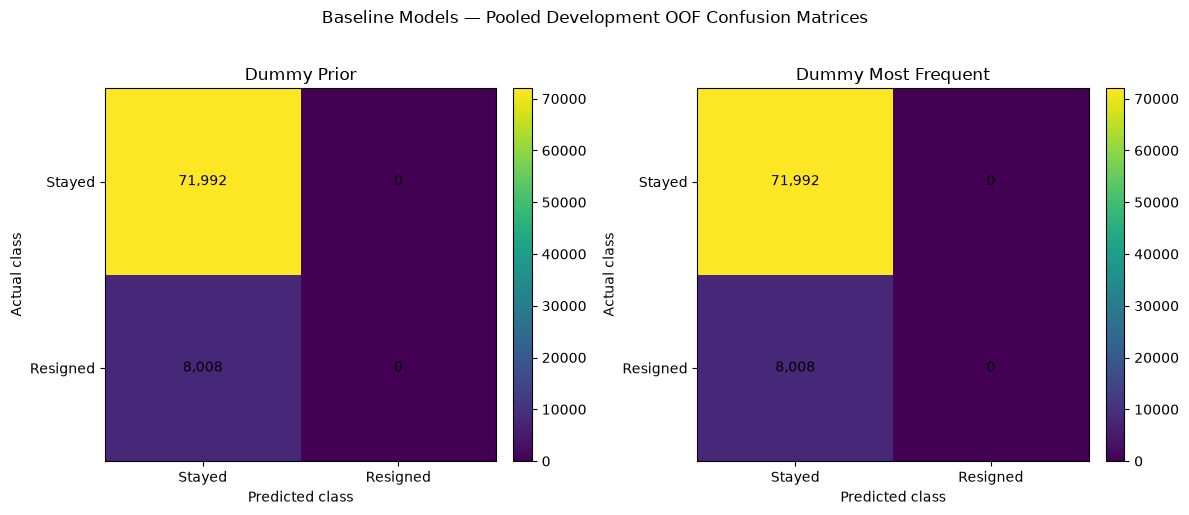

In [19]:
model_count = len(oof_predictions_by_model)
fig, axes = plt.subplots(1, model_count, figsize=(6 * model_count, 5))

if model_count == 1:
    axes = np.array([axes])
else:
    axes = np.asarray(axes).reshape(-1)

for ax, (model_name, predictions) in zip(axes, oof_predictions_by_model.items()):
    matrix = confusion_matrix(
        predictions["y_true"].astype(int),
        predictions["y_pred_0_5"].astype(int),
        labels=[0, 1],
    )
    image = ax.imshow(matrix, aspect="auto")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], labels=["Stayed", "Resigned"])
    ax.set_yticks([0, 1], labels=["Stayed", "Resigned"])

    for row_index in range(2):
        for column_index in range(2):
            ax.text(
                column_index,
                row_index,
                f"{matrix[row_index, column_index]:,}",
                ha="center",
                va="center",
            )
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Baseline Models — Pooled Development OOF Confusion Matrices", y=1.02)
fig.tight_layout()

confusion_matrix_figure_file = baseline_results_folder / "figure_01_baseline_confusion_matrices.png"
fig.savefig(confusion_matrix_figure_file, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

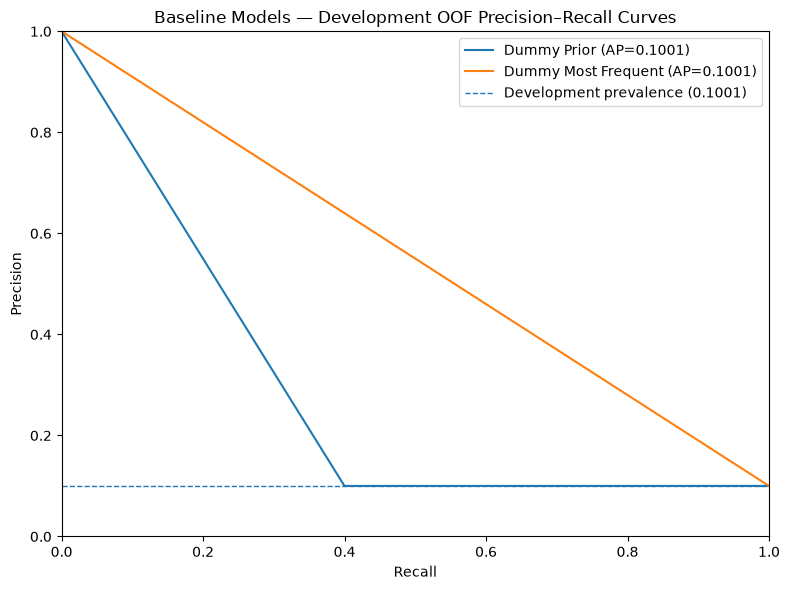

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, predictions in oof_predictions_by_model.items():
    precision_values, recall_values, _ = precision_recall_curve(
        predictions["y_true"].astype(int),
        predictions["y_probability"].astype(float),
    )
    model_pr_auc = average_precision_score(
        predictions["y_true"].astype(int),
        predictions["y_probability"].astype(float),
    )
    ax.plot(
        recall_values,
        precision_values,
        label=f"{model_name} (AP={model_pr_auc:.4f})",
    )

development_positive_rate = development_df[target_column].astype(int).mean()
ax.axhline(
    development_positive_rate,
    linestyle="--",
    linewidth=1,
    label=f"Development prevalence ({development_positive_rate:.4f})",
)

ax.set_title("Baseline Models — Development OOF Precision–Recall Curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

fig.tight_layout()

pr_curve_figure_file = baseline_results_folder / "figure_02_baseline_precision_recall_curves.png"
fig.savefig(pr_curve_figure_file, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

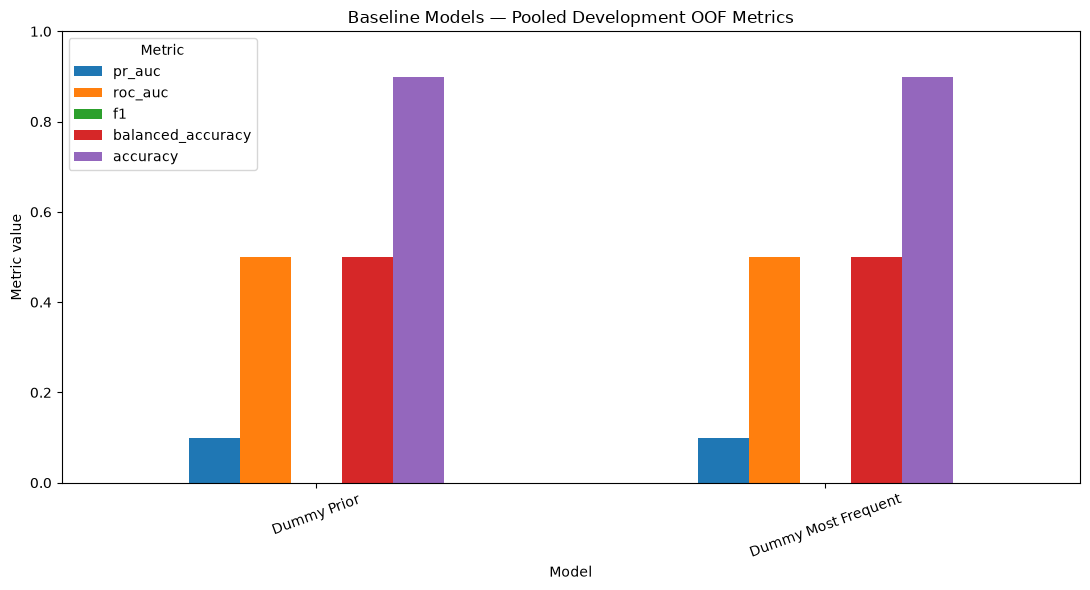

In [21]:
selected_metric_columns = ["pr_auc", "roc_auc", "f1", "balanced_accuracy", "accuracy"]
plot_metrics = baseline_summary_metrics[["model_name", *selected_metric_columns]].set_index("model_name")

fig, ax = plt.subplots(figsize=(11, 6))
plot_metrics.plot(kind="bar", ax=ax)

ax.set_title("Baseline Models — Pooled Development OOF Metrics")
ax.set_xlabel("Model")
ax.set_ylabel("Metric value")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Metric")

fig.tight_layout()

metric_comparison_figure_file = baseline_results_folder / "figure_03_baseline_metric_comparison.png"
fig.savefig(metric_comparison_figure_file, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

In [22]:
summary_by_model = baseline_summary_metrics.set_index("model_name")
baseline_interpretation_rows = []

prior_metrics = summary_by_model.loc[dummy_prior_model_name]
baseline_interpretation_rows.append(
    {
        "model_name": dummy_prior_model_name,
        "role": "No-skill probability / ranking reference",
        "pr_auc": prior_metrics["pr_auc"],
        "accuracy": prior_metrics["accuracy"],
        "recall": prior_metrics["recall"],
        "interpretation": "Uses only the training-fold class prior and provides no employee-level ranking signal.",
    }
)

most_frequent_metrics = summary_by_model.loc[dummy_most_frequent_model_name]
baseline_interpretation_rows.append(
    {
        "model_name": dummy_most_frequent_model_name,
        "role": "Majority-class classification reference",
        "pr_auc": most_frequent_metrics["pr_auc"],
        "accuracy": most_frequent_metrics["accuracy"],
        "recall": most_frequent_metrics["recall"],
        "interpretation": "Shows why high raw accuracy is misleading when the positive class is only about 10% of the development data.",
    }
)

baseline_interpretation = pd.DataFrame(baseline_interpretation_rows)
display(baseline_interpretation)

baseline_interpretation_file = baseline_results_folder / "baseline_interpretation.csv"
baseline_interpretation.to_csv(baseline_interpretation_file, index=False, encoding="utf-8", lineterminator="\n")

,model_name,role,pr_auc,accuracy,recall,interpretation
0,Dummy Prior,No-skill probability / ranking reference,0.100085,0.8999,0.0,Uses only the training-fold class prior and pr...
1,Dummy Most Frequent,Majority-class classification reference,0.100100,0.8999,0.0,Shows why high raw accuracy is misleading when...


## Baseline Interpretation

The mandatory Dummy models establish the minimum reference level for the project.

In [23]:
expected_baseline_outputs = [
    dummy_prior_oof_file,
    dummy_most_frequent_oof_file,
    combined_oof_file,
    baseline_fold_metrics_file,
    baseline_summary_metrics_file,
    baseline_interpretation_file,
    confusion_matrix_figure_file,
    pr_curve_figure_file,
    metric_comparison_figure_file,
    *confusion_matrix_files.values(),
]

output_manifest_rows = []
for output_file in expected_baseline_outputs:
    exists = output_file.exists()
    size_bytes = output_file.stat().st_size if exists else 0
    output_manifest_rows.append(
        {
            "file_name": output_file.name,
            "relative_path": str(output_file.relative_to(project_root)),
            "exists": exists,
            "size_bytes": size_bytes,
        }
    )

baseline_output_manifest = pd.DataFrame(output_manifest_rows)
display(baseline_output_manifest)

baseline_output_manifest_file = baseline_results_folder / "baseline_output_manifest.csv"
baseline_output_manifest.to_csv(baseline_output_manifest_file, index=False, encoding="utf-8", lineterminator="\n")

,file_name,relative_path,exists,size_bytes
0,dummy_prior_oof_predictions.csv,results\baselines\dummy_prior_oof_predictions.csv,True,2823251
1,dummy_most_frequent_oof_predictions.csv,results\baselines\dummy_most_frequent_oof_pred...,True,2871251
2,baseline_oof_predictions_combined.csv,results\baselines\baseline_oof_predictions_com...,True,5694439
3,baseline_fold_metrics.csv,results\baselines\baseline_fold_metrics.csv,True,1155
4,baseline_summary_metrics.csv,results\baselines\baseline_summary_metrics.csv,True,364
5,baseline_interpretation.csv,results\baselines\baseline_interpretation.csv,True,412
6,figure_01_baseline_confusion_matrices.png,results\baselines\figure_01_baseline_confusion...,True,56225
7,figure_02_baseline_precision_recall_curves.png,results\baselines\figure_02_baseline_precision...,True,82364
8,figure_03_baseline_metric_comparison.png,results\baselines\figure_03_baseline_metric_co...,True,49257
9,dummy_prior_confusion_matrix.csv,results\baselines\dummy_prior_confusion_matrix...,True,90


In [24]:
if sha256_file(raw_data_file) != expected_raw_sha256:
    raise ValueError("Final validation failed: raw dataset changed during baseline work.")
if sha256_file(split_registry_file) != expected_registry_sha256:
    raise ValueError("Final validation failed: split registry changed during baseline work.")

for model_name, predictions in oof_predictions_by_model.items():
    validate_oof_predictions(predictions, model_name)

print("FINAL BASELINE WORKFLOW VALIDATION")
print("-" * 60)
print("Baseline modelling validation: PASSED")

Dummy Prior: OOF validation PASSED (80,000 rows)
Dummy Most Frequent: OOF validation PASSED (80,000 rows)
FINAL BASELINE WORKFLOW VALIDATION
------------------------------------------------------------
Baseline modelling validation: PASSED


## Baseline Modelling Conclusion

The shared baseline workflow is complete. The mandatory no-skill references were evaluated using the frozen 80,000-row development partition and the exact five saved cross-validation folds.